# Tarea 2, Pregunta 2: Aprendizaje supervisado y semisupervisado

En esta pregunta usamos el dataset *Letter Recognition* del repositorio UCI. Tiene 20.000 imágenes de letras mayúsculas del alfabeto inglés, generadas a partir de 20 tipografías con distorsiones aleatorias. Cada imagen viene descrita por 16 características numéricas enteras, entre 0 y 15, que resumen la posición, el tamaño y la distribución de los píxeles, y la etiqueta $Y$ es la letra, con 26 clases. El dataset cumple los requisitos del enunciado (más de 15.000 filas, más de 7 características y una etiqueta discreta con más de dos clases) y es distinto del que usamos en la pregunta 1.

La pregunta de fondo es si vale la pena aprovechar los datos que no tienen etiqueta. Para responderla comparamos el aprendizaje supervisado, que entrena solo con las muestras etiquetadas, con el aprendizaje semisupervisado, que además asigna pseudoetiquetas a los datos no etiquetados a partir de un clustering.

El experimento sigue estos pasos:

1. División en 80 % entrenamiento y 20 % prueba. El conjunto de prueba no participa en ninguna decisión.
2. Dos escenarios: solo el 10 % o solo el 30 % del entrenamiento tiene etiqueta conocida.
3. Clustering del entrenamiento con K-Means y DBSCAN, con tres configuraciones por técnica.
4. Pseudoetiquetado que busca dejar el 60 % del entrenamiento con etiqueta, real o estimada.
5. Para cada uno de los seis enfoques (regresión logística y SVM, cada una supervisada, con K-Means o con DBSCAN), selección de hiperparámetros entre tres configuraciones por validación cruzada, usando solo etiquetas reales conocidas.
6. Evaluación final en prueba con tres semillas aleatorias y análisis de los resultados.

## 1. Librerías y configuración

Aquí quedan definidos la semilla de la división, las tres semillas del experimento, los dos escenarios y el objetivo de cobertura del 60 %. Todo lo demás depende de estos valores, así que cambiarlos aquí basta para repetir el experimento con otra configuración.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score, silhouette_score

warnings.filterwarnings('ignore', category=FutureWarning)

SEED_SPLIT = 42                       # semilla fija de la division entrenamiento / prueba
SEMILLAS = [0, 1, 2]                  # semillas para repetir todo el experimento
ESCENARIOS = {'10%': 0.10, '30%': 0.30}
OBJETIVO_COBERTURA = 0.60             # fraccion del entrenamiento que se busca dejar etiquetada
N_FOLDS = 5

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams['figure.dpi'] = 110

## 2. Carga y exploración de datos

El archivo `letter-recognition.data` no trae encabezado. La primera columna es la letra y las 16 siguientes son las características, a las que les pusimos los nombres de la documentación de UCI.

In [2]:
COLUMNAS = ['letra', 'x_box', 'y_box', 'width', 'high', 'onpix', 'x_bar', 'y_bar', 'x2bar',
            'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x_ege', 'xegvy', 'y_ege', 'yegvx']
df = pd.read_csv('Dataset/letter-recognition.data', header=None, names=COLUMNAS)

print('Dimensiones:', df.shape)
print('Clases:', df['letra'].nunique())
print('Valores nulos:', int(df.isna().sum().sum()))
print('Filas duplicadas:', int(df.duplicated().sum()))
df.head()

Dimensiones: (20000, 17)
Clases: 26
Valores nulos: 0
Filas duplicadas: 1332


,letra,x_box,y_box,width,high,onpix,x_bar,y_bar,x2bar,y2bar,xybar,x2ybr,xy2br,x_ege,xegvy,y_ege,yegvx
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


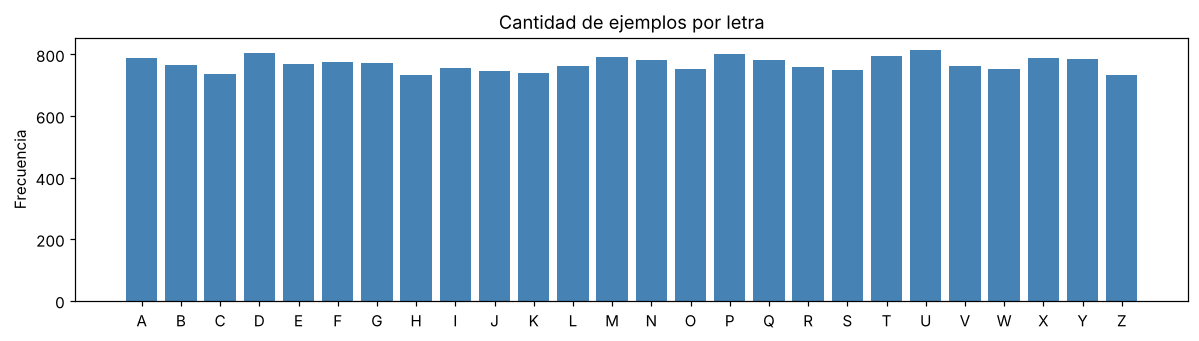

Minimo por clase: 734, maximo por clase: 813


In [3]:
conteo = df['letra'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(conteo.index, conteo.values, color='steelblue')
ax.set_title('Cantidad de ejemplos por letra')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()
print(f'Minimo por clase: {conteo.min()}, maximo por clase: {conteo.max()}')

Las 26 clases están prácticamente balanceadas, con entre 734 y 813 ejemplos cada una, y no hay valores nulos. Las 1.332 filas duplicadas tienen una explicación simple: como las características son enteros entre 0 y 15, dos imágenes distintas pueden quedar con exactamente la misma descripción. Son observaciones válidas, así que las mantenemos.

## 3. División de datos y escenarios

Separamos el 80 % de los datos para entrenamiento y el 20 % para prueba, de forma estratificada por letra y con una semilla fija. El conjunto de prueba es el mismo en todas las repeticiones, para que los resultados se puedan comparar entre semillas.

Las características se estandarizan con la media y la desviación estándar del entrenamiento, porque K-Means, DBSCAN, la SVM y la regresión logística regularizada dependen de distancias o de la escala de los coeficientes. Esto no filtra información: el escalador no usa etiquetas, y en un problema semisupervisado las características de los datos no etiquetados sí son conocidas.

En cada escenario elegimos al azar, de forma estratificada, el 10 % o el 30 % del entrenamiento como datos etiquetados. El resto se trata como no etiquetado, y sus etiquetas reales nunca se usan para entrenar ni para tomar decisiones. Solo las usamos al final, como diagnóstico, para medir qué tan buenas resultaron las pseudoetiquetas. Como la elección de los etiquetados depende de la semilla, cada una de las tres semillas genera un experimento distinto.

In [4]:
X = df.drop(columns='letra').values.astype(float)
y = df['letra'].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED_SPLIT)

scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
N_TRAIN = len(y_train)


def elegir_etiquetados(frac, semilla):
    idx, _ = train_test_split(np.arange(N_TRAIN), train_size=frac,
                              stratify=y_train, random_state=semilla)
    return np.sort(idx)


filas = []
for esc, frac in ESCENARIOS.items():
    n_lab = len(elegir_etiquetados(frac, SEMILLAS[0]))
    n_obj = int(round(OBJETIVO_COBERTURA * N_TRAIN))
    filas.append({'Escenario': esc, 'Etiquetados reales': n_lab, 'No etiquetados': N_TRAIN - n_lab,
                  'Objetivo 60%': n_obj, 'Pseudoetiquetas necesarias': n_obj - n_lab,
                  'Por clase (aprox.)': n_lab / 26})
print(f'Entrenamiento: {N_TRAIN} filas, prueba: {len(y_test)} filas')
pd.DataFrame(filas).set_index('Escenario')

Entrenamiento: 16000 filas, prueba: 4000 filas


,Etiquetados reales,No etiquetados,Objetivo 60%,Pseudoetiquetas necesarias,Por clase (aprox.)
Escenario,,,,,
10%,1600,14400,9600,8000,61.5385
30%,4800,11200,9600,4800,184.6154


Para llegar al 60 % del entrenamiento hay que pseudoetiquetar 8.000 de los 14.400 datos no etiquetados en el escenario del 10 %, es decir, el 56 % de ellos, y 4.800 de los 11.200 en el escenario del 30 %, que corresponden al 43 %. El escenario del 10 % es entonces el más exigente por partida doble: hay que estimar más etiquetas y con menos información para hacerlo, ya que cada letra tiene solo unos 62 ejemplos etiquetados.

## 4. Clustering: elección de configuraciones

### 4.1 K-Means

K-Means minimiza la suma de las distancias cuadradas de cada punto a su centroide (WCSS). Antes de elegir las configuraciones revisamos el método del codo y el coeficiente de silueta para un rango de valores de $k$. La silueta se calcula sobre una muestra de 4.000 puntos, porque sobre los 16.000 su costo es alto.

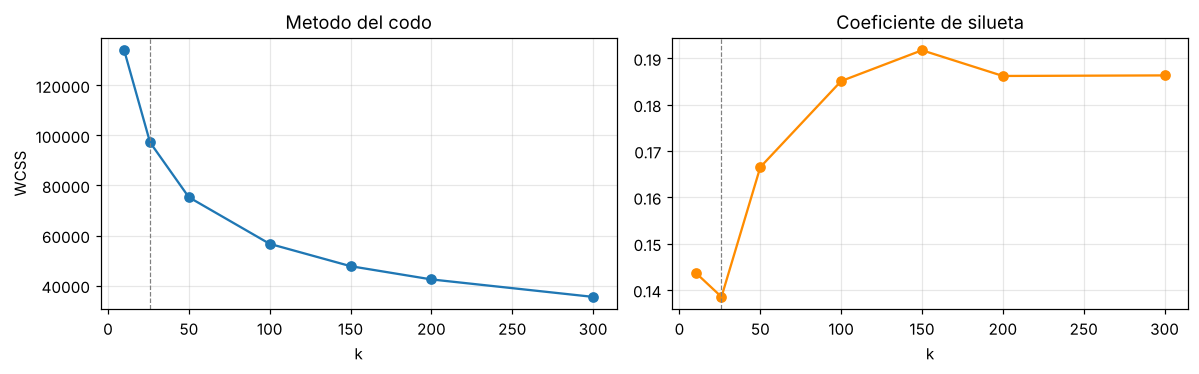

,WCSS,Silueta
k,,
10,"134,064.0513",0.1437
26,"97,246.2233",0.1385
50,"75,299.6571",0.1665
100,"56,664.2242",0.1851
150,"47,739.8740",0.1917
200,"42,442.8651",0.1862
300,"35,456.4589",0.1863


In [5]:
rng = np.random.default_rng(0)
muestra_sil = rng.choice(N_TRAIN, 4000, replace=False)   # la silueta se calcula sobre una muestra por costo

valores_k = [10, 26, 50, 100, 150, 200, 300]
codo = []
for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_train)
    codo.append({'k': k, 'WCSS': km.inertia_,
                 'Silueta': silhouette_score(X_train[muestra_sil], km.labels_[muestra_sil])})
codo = pd.DataFrame(codo).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(codo.index, codo['WCSS'], marker='o')
axes[0].set_title('Metodo del codo')
axes[0].set_xlabel('k')
axes[0].set_ylabel('WCSS')
axes[1].plot(codo.index, codo['Silueta'], marker='o', color='darkorange')
axes[1].set_title('Coeficiente de silueta')
axes[1].set_xlabel('k')
for ax in axes:
    ax.axvline(26, color='gray', ls='--', lw=0.8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
codo

La curva del codo baja de forma suave, sin un quiebre claro, y la silueta es baja para todos los valores de $k$, sin llegar nunca a 0,2. Esto indica que las letras no forman grupos naturales bien separados en este espacio: las distintas tipografías de una misma letra quedan lejos entre sí, y letras parecidas, como O y Q o H y N, se mezclan. Incluso con $k = 26$, un cluster por letra, la silueta (0,14) es más baja que con 100 o 200 clusters.

Por eso no elegimos $k$ con el codo, sino según lo que importa en esta pregunta, que es su utilidad para pseudoetiquetar. Probamos tres configuraciones:

- $k = 26$, un cluster por letra. Sería la elección natural si cada letra formara un grupo.
- $k = 100$ y $k = 200$, que corresponden a un sobreagrupamiento. Con más clusters cada uno es más pequeño y homogéneo, y tiende a contener una sola letra en una sola variante de tipografía, aunque varios clusters terminen correspondiendo a la misma letra. Esto mejora la pureza, a costa de tener menos ejemplos etiquetados por cluster para estimar su etiqueta.

### 4.2 DBSCAN

DBSCAN agrupa por densidad y usa dos parámetros: `eps`, el radio de vecindad, y `min_samples` ($n$), la cantidad mínima de puntos dentro de ese radio, contando al propio punto, para que un punto sea *core*. Los puntos que no se pueden alcanzar desde ningún *core* quedan como ruido. A diferencia de K-Means, no optimiza una función de costo.

Para elegir `eps` usamos el gráfico de distancia al $n$-ésimo vecino más cercano (*k-distance*), en el que cada punto se ordena según la distancia a su $n$-ésimo vecino.

n = 5: percentiles 25/50/75 de la distancia = [0.91 1.17 1.44]


n = 10: percentiles 25/50/75 de la distancia = [1.09 1.37 1.68]


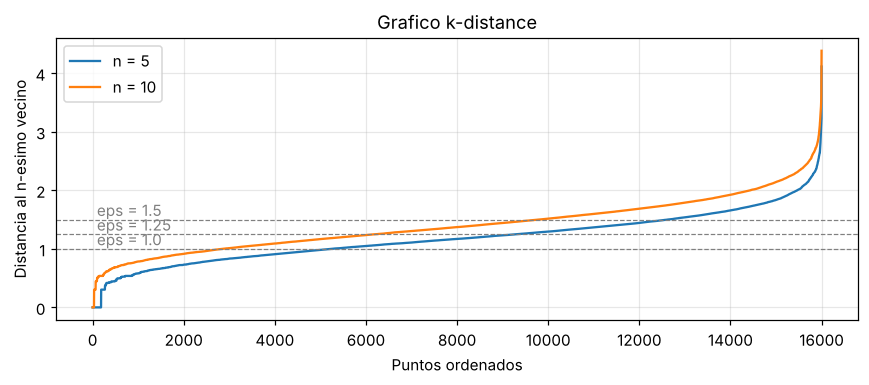

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for n_min in (5, 10):
    dist = NearestNeighbors(n_neighbors=n_min).fit(X_train).kneighbors(X_train)[0][:, -1]
    ax.plot(np.sort(dist), label=f'n = {n_min}')
    print(f'n = {n_min}: percentiles 25/50/75 de la distancia = {np.percentile(dist, [25, 50, 75]).round(2)}')
for eps in (1.0, 1.25, 1.5):
    ax.axhline(eps, color='gray', ls='--', lw=0.8)
    ax.text(0, eps, f' eps = {eps}', va='bottom', color='gray')
ax.set_xlabel('Puntos ordenados')
ax.set_ylabel('Distancia al n-esimo vecino')
ax.set_title('Grafico k-distance')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La curva sube de forma gradual, sin un codo marcado, lo que muestra que la densidad cambia mucho entre regiones del espacio. Eso anticipa el problema que va a tener DBSCAN en este dataset. Con un `eps` pequeño, solo las regiones densas forman clusters y muchos puntos quedan como ruido. Con un `eps` grande, las regiones se conectan entre sí y aparece un cluster gigante que mezcla muchas letras.

Probamos tres configuraciones ubicadas alrededor de la mediana de la curva:

- `eps = 1,0` y $n = 5$: configuración conservadora, con clusters densos y puros pero mucho ruido.
- `eps = 1,25` y $n = 10$: radio intermedio, exigiendo más vecinos para ser *core*.
- `eps = 1,5` y $n = 10$: radio amplio, que conecta a la mayoría de los puntos.

In [7]:
CONFIG_KMEANS = {'K-Means k=26': 26, 'K-Means k=100': 100, 'K-Means k=200': 200}
CONFIG_DBSCAN = {'DBSCAN eps=1.0 n=5': (1.0, 5),
                 'DBSCAN eps=1.25 n=10': (1.25, 10),
                 'DBSCAN eps=1.5 n=10': (1.5, 10)}


def ajustar_kmeans(k, semilla):
    km = KMeans(n_clusters=k, n_init=10, random_state=semilla).fit(X_train)
    clusters = km.labels_
    dist = np.linalg.norm(X_train - km.cluster_centers_[clusters], axis=1)
    # cercania: 1 para el punto mas cercano al centroide de su cluster, cercano a 0 para el mas lejano
    cercania = np.zeros(N_TRAIN)
    for c in range(k):
        m = clusters == c
        rango = dist[m].argsort().argsort()
        cercania[m] = 1 - rango / m.sum()
    return {'clusters': clusters, 'cercania': cercania, 'wcss': km.inertia_}


def ajustar_dbscan(eps, n_min):
    db = DBSCAN(eps=eps, min_samples=n_min).fit(X_train)
    clusters = db.labels_
    # cercania: 1 para puntos core, 0.5 para puntos borde, 0 para ruido
    cercania = np.where(clusters == -1, 0.0, 0.5)
    cercania[db.core_sample_indices_] = 1.0
    return {'clusters': clusters, 'cercania': cercania, 'wcss': np.nan}


def describir_clustering(nombre, info):
    c = info['clusters']
    en_cluster = c != -1
    tam = np.bincount(c[en_cluster]) if en_cluster.any() else np.array([0])
    m = muestra_sil[en_cluster[muestra_sil]]
    sil = silhouette_score(X_train[m], c[m]) if len(np.unique(c[m])) > 1 else np.nan
    return {'Configuracion': nombre, 'Clusters': int(c.max() + 1), 'Ruido (%)': 100 * (~en_cluster).mean(),
            'Cluster mas grande': int(tam.max()), 'WCSS': info['wcss'], 'Silueta': sil}


inicio = time.time()
infos_kmeans = {s: {nombre: ajustar_kmeans(k, s) for nombre, k in CONFIG_KMEANS.items()} for s in SEMILLAS}
infos_dbscan = {nombre: ajustar_dbscan(*p) for nombre, p in CONFIG_DBSCAN.items()}
print(f'Clustering listo en {time.time() - inicio:.1f} s')

desc = [describir_clustering(n, i) for n, i in infos_kmeans[SEMILLAS[0]].items()]
desc += [describir_clustering(n, i) for n, i in infos_dbscan.items()]
pd.DataFrame(desc).set_index('Configuracion')

Clustering listo en 18.8 s


,Clusters,Ruido (%),Cluster mas grande,WCSS,Silueta
Configuracion,,,,,
K-Means k=26,26,0.0000,1266,"97,246.2233",0.1385
K-Means k=100,100,0.0000,402,"56,664.2242",0.1851
K-Means k=200,200,0.0000,197,"42,442.8651",0.1862
DBSCAN eps=1.0 n=5,218,56.2813,474,NaN,0.1705
DBSCAN eps=1.25 n=10,71,44.5000,3350,NaN,0.0742
DBSCAN eps=1.5 n=10,50,22.2312,9335,NaN,-0.1705


K-Means se ajusta una vez por semilla, porque su resultado depende de la inicialización de los centroides. DBSCAN, en cambio, es determinista para un mismo conjunto de datos, así que basta con ajustarlo una vez. Ninguno de los dos usa etiquetas: el clustering se hace sobre los 16.000 datos de entrenamiento, etiquetados y no etiquetados.

La tabla confirma lo que anticipaba el gráfico *k-distance*. Con `eps = 1,0` más de la mitad de los datos (56 %) queda como ruido. Con `eps = 1,5` el ruido baja al 22 %, pero a cambio aparece un cluster de 9.335 puntos que agrupa a la mayoría de los datos, y la silueta pasa a ser negativa.

## 5. Estrategia de pseudoetiquetado

La idea es usar los pocos datos etiquetados para ponerle nombre a cada cluster y luego propagar ese nombre a los datos no etiquetados del mismo cluster, empezando por los más confiables. El procedimiento tiene cuatro pasos.

**Etiqueta de cada cluster.** Para cada cluster miramos los datos etiquetados que contiene. Su etiqueta es la letra mayoritaria, y su pureza es la fracción de esos etiquetados que tiene esa letra.

**Clusters confiables.** Un cluster solo se usa si tiene al menos 3 datos etiquetados, para que la mayoría no dependa de uno o dos ejemplos, y si su pureza es de al menos 50 %, es decir, si la letra mayoritaria representa como mínimo la mitad de los etiquetados. Los clusters que no cumplen estas condiciones, y los puntos de ruido de DBSCAN, no reciben pseudoetiquetas, porque no hay evidencia suficiente para asignarles una letra.

**Confianza de cada punto.** Cada dato no etiquetado de un cluster confiable recibe una confianza igual a la pureza del cluster multiplicada por su cercanía. En K-Means, la cercanía mide qué tan cerca está el punto del centroide, como un valor entre 0 y 1 según su posición dentro del cluster: los puntos del centro son los más representativos, y los de la periferia podrían pertenecer a otra letra. En DBSCAN, la cercanía vale 1 para los puntos *core* y 0,5 para los puntos borde, que están en el límite de la región densa.

**Selección.** Ordenamos los candidatos por confianza y asignamos pseudoetiquetas a los más confiables, hasta que etiquetados y pseudoetiquetados juntos lleguen al 60 % del entrenamiento. Si no hay suficientes candidatos confiables, se asignan todos los que hay y la cobertura queda bajo el 60 %.

Para elegir una configuración de clustering por técnica usamos la cantidad esperada de pseudoetiquetas correctas, que es la cantidad de pseudoetiquetas asignadas multiplicada por su precisión estimada. Este criterio equilibra cantidad y calidad: no gana una configuración que cubre mucho pero se equivoca seguido, ni tampoco una muy precisa que casi no asigna etiquetas.

La precisión estimada se calcula solo con etiquetas conocidas, mediante validación cruzada sobre los etiquetados. Escondemos una parte de ellos, nombramos los clusters con el resto y medimos cuántos de los escondidos reciben la letra correcta.

In [8]:
TAU_PUREZA = 0.5
MIN_ETIQUETADOS = 3


def clusters_confiables(clusters, idx_lab, y_lab):
    tabla = pd.DataFrame({'cluster': clusters[idx_lab], 'y': y_lab})
    tabla = tabla[tabla['cluster'] != -1]
    resumen = tabla.groupby('cluster')['y'].agg(
        n='size',
        etiqueta=lambda v: v.value_counts().index[0],
        pureza=lambda v: v.value_counts(normalize=True).iloc[0])
    return resumen[(resumen['n'] >= MIN_ETIQUETADOS) & (resumen['pureza'] >= TAU_PUREZA)]


def pseudoetiquetar(info, idx_lab, y_lab, n_objetivo, excluir=None):
    clusters, cercania = info['clusters'], info['cercania']
    confiables = clusters_confiables(clusters, idx_lab, y_lab)
    disponible = np.ones(N_TRAIN, dtype=bool)
    disponible[idx_lab] = False
    if excluir is not None:
        disponible[excluir] = False
    candidatos = np.where(disponible & np.isin(clusters, confiables.index))[0]
    confianza = confiables['pureza'].reindex(clusters[candidatos]).values * cercania[candidatos]
    elegidos = candidatos[np.argsort(-confianza, kind='stable')][:n_objetivo]
    etiquetas = confiables['etiqueta'].reindex(clusters[elegidos]).values
    return elegidos, etiquetas, len(candidatos)


def estimar_precision_pseudo(info, idx_lab, y_lab, semilla):
    # Solo usa etiquetas conocidas: esconde un fold de etiquetados y mide si su cluster lo nombra bien
    clusters = info['clusters']
    aciertos, total = 0, 0
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla)
    for a, b in skf.split(idx_lab, y_lab):
        conf = clusters_confiables(clusters, idx_lab[a], y_lab[a])
        c_b = clusters[idx_lab[b]]
        cubiertos = np.isin(c_b, conf.index)
        aciertos += (conf['etiqueta'].reindex(c_b[cubiertos]).values == y_lab[b][cubiertos]).sum()
        total += cubiertos.sum()
    return aciertos / total if total else np.nan

## 6. Clasificadores, configuraciones de hiperparámetros y funciones de pérdida

| Modelo | Función de pérdida | Configuraciones evaluadas | Justificación |
|---|---|---|---|
| Regresión logística (multinomial) | Entropía cruzada (log-loss) más penalización L2 $\frac{1}{2C}\lVert\theta\rVert^2$ | `C = 0,01`, `C = 1`, `C = 100` | `C` es el inverso de la fuerza de regularización (clase 14). Recorremos tres órdenes de magnitud: regularización fuerte, la opción por defecto y regularización débil. |
| SVM | Hinge loss (margen suave) más penalización L2 $\frac{1}{2}\lVert\theta\rVert^2$, con el error ponderado por `C` | Lineal con `C = 1`, RBF con `C = 1`, RBF con `C = 10` | La versión lineal permite comparar con la regresión logística usando el mismo tipo de frontera. El kernel RBF (*kernel trick*, clase 13) permite fronteras no lineales, y `C` controla el equilibrio entre un margen amplio y los errores en entrenamiento. |

Para las 26 clases, la regresión logística usa la generalización multinomial (softmax) y `SVC` usa la estrategia uno contra uno. El kernel RBF usa `gamma='scale'`, que ajusta el ancho del kernel a la varianza de los datos.

Como métrica principal usamos el F1 macro, que promedia el F1 de cada letra y le da el mismo peso a las 26 clases. Lo preferimos porque el pseudoetiquetado puede desbalancear las clases del conjunto de entrenamiento, y una métrica que pondera todas las letras por igual detecta si el modelo empieza a descuidar alguna. También reportamos el accuracy como referencia; como el conjunto de prueba está balanceado, resulta muy parecido al F1 macro.

La selección de hiperparámetros tiene una dificultad que conviene dejar clara: no podemos validar contra datos sin etiqueta. Por eso, para cada combinación de clasificador y enfoque hacemos una validación cruzada de 5 folds solo sobre los datos con etiqueta real. En el enfoque supervisado esto es directo, porque cada fold entrena con 4/5 de los etiquetados y valida con el 1/5 restante. En los enfoques semisupervisados, en cada fold rehacemos el pseudoetiquetado usando solo las etiquetas reales de los 4/5 de entrenamiento, y los etiquetados del fold de validación quedan excluidos de recibir pseudoetiquetas. El modelo se entrena con etiquetados más pseudoetiquetados y se valida solo con las etiquetas reales del fold de validación.

Así ninguna decisión usa las etiquetas desconocidas ni el conjunto de prueba, y la validación mide el desempeño contra etiquetas verdaderas y no contra pseudoetiquetas que podrían estar equivocadas.

In [9]:
CONFIG_CLASIFICADORES = {
    'Regresion logistica': {
        'C=0.01': LogisticRegression(C=0.01, max_iter=3000),
        'C=1': LogisticRegression(C=1, max_iter=3000),
        'C=100': LogisticRegression(C=100, max_iter=3000),
    },
    'SVM': {
        'lineal C=1': SVC(kernel='linear', C=1),
        'RBF C=1': SVC(kernel='rbf', C=1, gamma='scale'),
        'RBF C=10': SVC(kernel='rbf', C=10, gamma='scale'),
    },
}
ENFOQUES = ['Supervisado', 'K-Means', 'DBSCAN']


def evaluar_fold(modelo, idx_fit, y_fit, idx_val):
    m = clone(modelo).fit(X_train[idx_fit], y_fit)
    pred = m.predict(X_train[idx_val])
    return f1_score(y_train[idx_val], pred, average='macro'), accuracy_score(y_train[idx_val], pred)


def nombre_enfoque(clasificador, enfoque):
    return f'{clasificador} (supervisado)' if enfoque == 'Supervisado' else f'{clasificador} + {enfoque}'

## 7. Experimento completo

Para cada semilla y cada escenario, la celda siguiente ejecuta el experimento en cuatro pasos:

1. Selección de los datos etiquetados.
2. Evaluación de las tres configuraciones de K-Means y de DBSCAN para pseudoetiquetar, y elección de una por técnica.
3. Validación cruzada de las tres configuraciones de hiperparámetros en los seis enfoques.
4. Entrenamiento de cada enfoque con su mejor configuración sobre todos sus datos (los etiquetados, más los pseudoetiquetados en los enfoques semisupervisados) y evaluación en prueba.

Todas las configuraciones evaluadas quedan registradas. La ejecución completa toma unos tres minutos, la mayor parte por la SVM con kernel RBF.

In [10]:
registro_clustering, registro_cv, registro_test = [], [], []
inicio_total = time.time()

for semilla in SEMILLAS:
    for esc, frac in ESCENARIOS.items():
        t0 = time.time()
        idx_lab = elegir_etiquetados(frac, semilla)
        y_lab = y_train[idx_lab]
        n_obj = int(round(OBJETIVO_COBERTURA * N_TRAIN)) - len(idx_lab)

        # 1) Configuracion de clustering para cada tecnica
        info_elegida, pseudo_final = {}, {}
        for tecnica, infos in [('K-Means', infos_kmeans[semilla]), ('DBSCAN', infos_dbscan)]:
            mejor, mejor_valor = None, -1
            for nombre, info in infos.items():
                sel, etq, n_cand = pseudoetiquetar(info, idx_lab, y_lab, n_obj)
                est = estimar_precision_pseudo(info, idx_lab, y_lab, semilla)
                esperadas = len(sel) * est
                registro_clustering.append({
                    'Semilla': semilla, 'Escenario': esc, 'Tecnica': tecnica, 'Configuracion': nombre,
                    'Candidatos': n_cand, 'Pseudoetiquetas': len(sel),
                    'Cobertura total': (len(idx_lab) + len(sel)) / N_TRAIN,
                    'Precision estimada': est, 'Correctas esperadas': esperadas,
                    'Precision real (diagnostico)': (etq == y_train[sel]).mean() if len(sel) else np.nan})
                if esperadas > mejor_valor:
                    mejor, mejor_valor = nombre, esperadas
                    info_elegida[tecnica] = info
                    pseudo_final[tecnica] = (sel, etq)
            for fila in registro_clustering[-len(infos):]:
                fila['Elegida'] = fila['Configuracion'] == mejor

        # 2) Folds de validacion cruzada (solo etiquetas reales para validar)
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla)
        folds = {e: [] for e in ENFOQUES}
        for a, b in skf.split(idx_lab, y_lab):
            tr, va = idx_lab[a], idx_lab[b]
            folds['Supervisado'].append((tr, y_train[tr], va))
            for tecnica in ('K-Means', 'DBSCAN'):
                sel, etq, _ = pseudoetiquetar(info_elegida[tecnica], tr, y_train[tr], n_obj, excluir=va)
                folds[tecnica].append((np.r_[tr, sel], np.r_[y_train[tr], etq], va))

        # Conjuntos finales de entrenamiento de cada enfoque
        finales = {'Supervisado': (idx_lab, y_lab)}
        for tecnica, (sel, etq) in pseudo_final.items():
            finales[tecnica] = (np.r_[idx_lab, sel], np.r_[y_lab, etq])

        # 3) Seleccion de hiperparametros y 4) evaluacion en prueba
        for clasificador, configs in CONFIG_CLASIFICADORES.items():
            for enfoque in ENFOQUES:
                resultados = {}
                for nombre_cfg, modelo in configs.items():
                    res = Parallel(n_jobs=-1)(delayed(evaluar_fold)(modelo, f, yf, v) for f, yf, v in folds[enfoque])
                    f1s, accs = np.array(res).T
                    resultados[nombre_cfg] = f1s.mean()
                    registro_cv.append({
                        'Semilla': semilla, 'Escenario': esc, 'Clasificador': clasificador, 'Enfoque': enfoque,
                        'Nombre': nombre_enfoque(clasificador, enfoque), 'Hiperparametros': nombre_cfg,
                        'F1 macro CV': f1s.mean(), 'F1 macro CV (std)': f1s.std(), 'Accuracy CV': accs.mean()})
                mejor_cfg = max(resultados, key=resultados.get)
                for fila in registro_cv[-len(configs):]:
                    fila['Elegida'] = fila['Hiperparametros'] == mejor_cfg

                idx_fit, y_fit = finales[enfoque]
                modelo = clone(configs[mejor_cfg]).fit(X_train[idx_fit], y_fit)
                pred = modelo.predict(X_test)
                registro_test.append({
                    'Semilla': semilla, 'Escenario': esc, 'Clasificador': clasificador, 'Enfoque': enfoque,
                    'Nombre': nombre_enfoque(clasificador, enfoque), 'Hiperparametros': mejor_cfg,
                    'Datos de entrenamiento': len(idx_fit),
                    'F1 macro test': f1_score(y_test, pred, average='macro'),
                    'Accuracy test': accuracy_score(y_test, pred)})
        print(f'Semilla {semilla}, escenario {esc}: {time.time() - t0:.0f} s')

df_clu = pd.DataFrame(registro_clustering)
df_cv = pd.DataFrame(registro_cv)
df_test = pd.DataFrame(registro_test)
print(f'Tiempo total: {(time.time() - inicio_total) / 60:.1f} min')

Semilla 0, escenario 10%: 22 s


Semilla 0, escenario 30%: 33 s


Semilla 1, escenario 10%: 22 s


Semilla 1, escenario 30%: 33 s


Semilla 2, escenario 10%: 21 s


Semilla 2, escenario 30%: 33 s
Tiempo total: 2.7 min


## 8. Resultados del pseudoetiquetado

La tabla resume cada configuración de clustering con el promedio de las tres semillas. La columna de precisión real usa las etiquetas ocultas, así que la mostramos solo como diagnóstico, para evaluar qué tan buena fue la estimación. No se usó para elegir nada.

In [11]:
resumen_clu = (df_clu.groupby(['Escenario', 'Tecnica', 'Configuracion'], sort=False)
               .agg(Pseudoetiquetas=('Pseudoetiquetas', 'mean'),
                    Cobertura_total=('Cobertura total', 'mean'),
                    Precision_estimada=('Precision estimada', 'mean'),
                    Precision_real=('Precision real (diagnostico)', 'mean'),
                    Correctas_esperadas=('Correctas esperadas', 'mean'),
                    Veces_elegida=('Elegida', 'sum')))
resumen_clu

Pseudoetiquetas  Cobertura_total  \
Escenario Tecnica Configuracion                                            
10%       K-Means K-Means k=26               2,272.0000           0.2420   
                  K-Means k=100              7,281.3333           0.5551   
                  K-Means k=200              8,000.0000           0.6000   
          DBSCAN  DBSCAN eps=1.0 n=5         4,457.3333           0.3786   
                  DBSCAN eps=1.25 n=10       4,034.0000           0.3521   
                  DBSCAN eps=1.5 n=10        2,101.6667           0.2314   
30%       K-Means K-Means k=26               1,549.6667           0.3969   
                  K-Means k=100              4,800.0000           0.6000   
                  K-Means k=200              4,800.0000           0.6000   
          DBSCAN  DBSCAN eps=1.0 n=5         3,920.3333           0.5450   
                  DBSCAN eps=1.25 n=10       3,521.0000           0.5201   
                  DBSCAN eps=1.5 n=10        1,827.6667           0.4142   

                                        Precision_estimada  Precision_real  \
Escenario Tecnica Configuracion                                              
10%       K-Means K-Means k=26                      0.6318          0.6654   
                  K-Means k=100                     0.7349          0.7420   
                  K-Means k=200                     0.7410          0.7938   
          DBSCAN  DBSCAN eps=1.0 n=5                0.8191          0.8447   
                  DBSCAN eps=1.25 n=10              0.8656          0.8885   
                  DBSCAN eps=1.5 n=10               0.9839          0.9814   
30%       K-Means K-Means k=26                      0.6910          0.7099   
                  K-Means k=100                     0.7807          0.8004   
                  K-Means k=200                     0.8002          0.8809   
          DBSCAN  DBSCAN eps=1.0 n=5                0.8659          0.8784   
                  DBSCAN eps=1.25 n=10              0.8717          0.8738   
                  DBSCAN eps=1.5 n=10               0.9707          0.9732   

                                        Correctas_esperadas  Veces_elegida  
Escenario Tecnica Configuracion                                             
10%       K-Means K-Means k=26                   1,432.5179              0  
                  K-Means k=100                  5,344.7827              0  
                  K-Means k=200                  5,927.9612              3  
          DBSCAN  DBSCAN eps=1.0 n=5             3,655.4517              3  
                  DBSCAN eps=1.25 n=10           3,477.2386              0  
                  DBSCAN eps=1.5 n=10            2,067.7304              0  
30%       K-Means K-Means k=26                   1,069.8083              0  
                  K-Means k=100                  3,747.4395              0  
                  K-Means k=200                  3,840.8787              3  
          DBSCAN  DBSCAN eps=1.0 n=5             3,393.0619              3  
                  DBSCAN eps=1.25 n=10           3,069.2195              0  
                  DBSCAN eps=1.5 n=10            1,773.9849              0

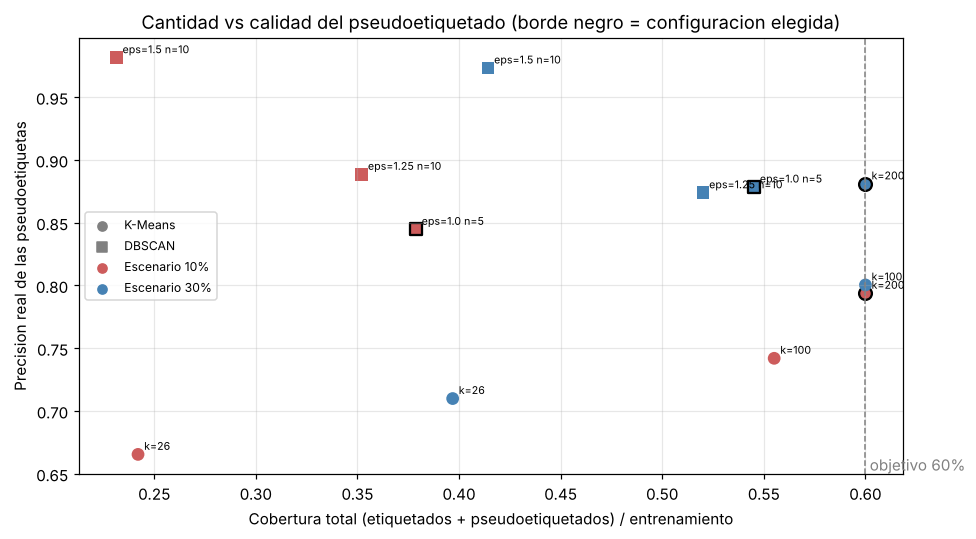

In [12]:
marcas = {'K-Means': 'o', 'DBSCAN': 's'}
colores = {'10%': 'indianred', '30%': 'steelblue'}
fig, ax = plt.subplots(figsize=(9, 5))
for (esc, tec, conf), fila in resumen_clu.iterrows():
    ax.scatter(fila['Cobertura_total'], fila['Precision_real'], marker=marcas[tec], color=colores[esc],
               s=70, edgecolor='black' if fila['Veces_elegida'] > 0 else 'none', linewidth=1.5)
    ax.annotate(conf.replace('K-Means ', '').replace('DBSCAN ', ''),
                (fila['Cobertura_total'], fila['Precision_real']), fontsize=7,
                xytext=(4, 3), textcoords='offset points')
ax.axvline(OBJETIVO_COBERTURA, color='gray', ls='--', lw=1)
ax.text(OBJETIVO_COBERTURA, ax.get_ylim()[0], ' objetivo 60%', color='gray', va='bottom')
for tec, mk in marcas.items():
    ax.scatter([], [], marker=mk, color='gray', label=tec)
for esc, col in colores.items():
    ax.scatter([], [], marker='o', color=col, label=f'Escenario {esc}')
ax.set_xlabel('Cobertura total (etiquetados + pseudoetiquetados) / entrenamiento')
ax.set_ylabel('Precision real de las pseudoetiquetas')
ax.set_title('Cantidad vs calidad del pseudoetiquetado (borde negro = configuracion elegida)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis del pseudoetiquetado

K-Means con $k = 26$ es la peor opción. Cubre solo el 24 % del entrenamiento en el escenario del 10 % y el 40 % en el del 30 %, con una precisión de entre 67 % y 71 %. Como cada cluster mezcla varias letras, pocos superan el filtro de pureza, y los que lo superan siguen estando bastante mezclados.

El sobreagrupamiento mejora la cantidad y la calidad al mismo tiempo. Con $k = 200$ se alcanza el 60 % en ambos escenarios, con una precisión de 79 % en el escenario del 10 % y de 88 % en el del 30 %. Fue la configuración elegida en las tres semillas de ambos escenarios.

DBSCAN, en cambio, no logra el 60 % en ningún caso. Su mejor configuración, `eps = 1,0`, llega al 38 % en el escenario del 10 % y al 55 % en el del 30 %. Esta es la limitación que impide cumplir el objetivo, y se explica por cómo funciona el algoritmo con este dataset. Con un `eps` pequeño, más de la mitad de los puntos queda como ruido, y como el ruido no pertenece a ningún cluster, no hay una forma justificada de asignarle una letra. Con un `eps` grande, las regiones se conectan y aparece un cluster gigante, de más de 9.000 puntos con `eps = 1,5`, que mezcla casi todas las letras. Su pureza no llega al 50 %, así que queda fuera, y la cobertura baja en vez de subir (23 % y 41 %), aunque las pocas pseudoetiquetas que quedan son casi perfectas, con una precisión de 97 % a 98 %.

El problema de fondo es que DBSCAN usa un único umbral de densidad para todo el espacio, y la densidad de estos datos varía mucho entre regiones, como mostró el gráfico *k-distance*. Para llegar al 60 % habría que aceptar el cluster gigante o los puntos de ruido, lo que significaría asignar miles de etiquetas con una alta probabilidad de error. Decidimos priorizar la calidad sobre la cantidad.

La precisión estimada solo con etiquetas conocidas se parece mucho a la real, así que el criterio de elección es confiable sin necesidad de mirar las etiquetas ocultas. En K-Means con $k = 200$ la estimación resulta algo pesimista (74 % frente a 79 % en el escenario del 10 %), porque los puntos elegidos son los de mayor confianza, y esos aciertan más que el promedio de su cluster.

Por último, más etiquetas reales producen mejores pseudoetiquetas. Con $k = 200$, la precisión sube de 79 % a 88 % al pasar del 10 % al 30 % de etiquetados. Hay dos razones: cada cluster tiene más etiquetados para nombrarlo bien, y como se necesitan menos pseudoetiquetas (4.800 en vez de 8.000), solo se usan las más confiables.

## 9. Selección de hiperparámetros: todas las configuraciones evaluadas

La tabla completa (`df_cv`) guarda cada configuración de cada semilla y escenario. Aquí mostramos el promedio de las tres semillas y cuántas veces fue elegida cada configuración.

In [13]:
resumen_cv = (df_cv.groupby(['Escenario', 'Nombre', 'Hiperparametros'], sort=False)
              .agg(F1_CV=('F1 macro CV', 'mean'), F1_CV_std_folds=('F1 macro CV (std)', 'mean'),
                   Accuracy_CV=('Accuracy CV', 'mean'), Veces_elegida=('Elegida', 'sum')))
resumen_cv

F1_CV  \
Escenario Nombre                            Hiperparametros          
10%       Regresion logistica (supervisado) C=0.01          0.5489   
                                            C=1             0.7345   
                                            C=100           0.7294   
          Regresion logistica + K-Means     C=0.01          0.5885   
                                            C=1             0.6563   
                                            C=100           0.6586   
          Regresion logistica + DBSCAN      C=0.01          0.5082   
                                            C=1             0.6585   
                                            C=100           0.6788   
          SVM (supervisado)                 lineal C=1      0.7949   
                                            RBF C=1         0.7944   
                                            RBF C=10        0.8582   
          SVM + K-Means                     lineal C=1      0.6782   
                                            RBF C=1         0.6621   
                                            RBF C=10        0.7089   
          SVM + DBSCAN                      lineal C=1      0.7258   
                                            RBF C=1         0.7272   
                                            RBF C=10        0.7873   
30%       Regresion logistica (supervisado) C=0.01          0.6483   
                                            C=1             0.7517   
                                            C=100           0.7563   
          Regresion logistica + K-Means     C=0.01          0.6287   
                                            C=1             0.7336   
                                            C=100           0.7369   
          Regresion logistica + DBSCAN      C=0.01          0.6131   
                                            C=1             0.7216   
                                            C=100           0.7307   
          SVM (supervisado)                 lineal C=1      0.8303   
                                            RBF C=1         0.8792   
                                            RBF C=10        0.9300   
          SVM + K-Means                     lineal C=1      0.7950   
                                            RBF C=1         0.8186   
                                            RBF C=10        0.8665   
          SVM + DBSCAN                      lineal C=1      0.7836   
                                            RBF C=1         0.8239   
                                            RBF C=10        0.8780   

                                                             F1_CV_std_folds  \
Escenario Nombre                            Hiperparametros                    
10%       Regresion logistica (supervisado) C=0.01                    0.0219   
                                            C=1                       0.0218   
                                            C=100                     0.0209   
          Regresion logistica + K-Means     C=0.01                    0.0289   
                                            C=1                       0.0262   
                                            C=100                     0.0223   
          Regresion logistica + DBSCAN      C=0.01                    0.0207   
                                            C=1                       0.0193   
                                            C=100                     0.0233   
          SVM (supervisado)                 lineal C=1                0.0252   
                                            RBF C=1                   0.0145   
                                            RBF C=10                  0.0156   
          SVM + K-Means                     lineal C=1                0.0164   
                                            RBF C=1                   0.0227   
                                            RBF C=10                  0.0238   
          SVM + DBSCAN                  

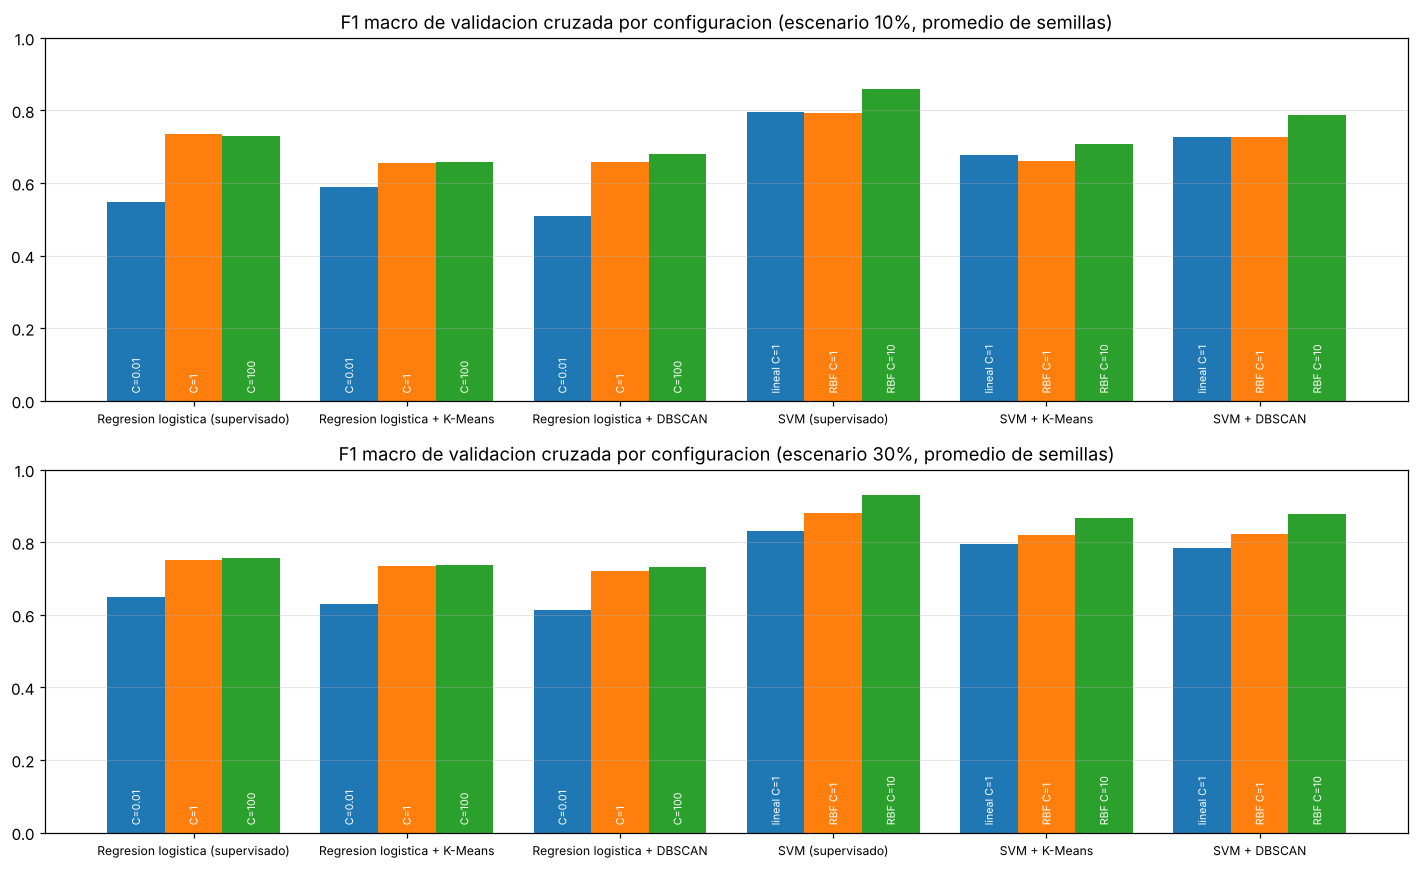

In [14]:
nombres = df_cv['Nombre'].unique()
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharey=True)
for ax, esc in zip(axes, ESCENARIOS):
    sub = resumen_cv.loc[esc].reset_index()
    ancho = 0.27
    for j, pos in enumerate(range(3)):
        vals, etiquetas = [], []
        for n in nombres:
            filas_n = sub[sub['Nombre'] == n].iloc[pos]
            vals.append(filas_n['F1_CV'])
            etiquetas.append(filas_n['Hiperparametros'])
        barras = ax.bar(np.arange(len(nombres)) + (j - 1) * ancho, vals, ancho)
        for b, et in zip(barras, etiquetas):
            ax.text(b.get_x() + b.get_width() / 2, 0.02, et, rotation=90, ha='center', va='bottom',
                    fontsize=7, color='white')
    ax.set_xticks(np.arange(len(nombres)), nombres, fontsize=8)
    ax.set_title(f'F1 macro de validacion cruzada por configuracion (escenario {esc}, promedio de semillas)')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis de los hiperparámetros

En la regresión logística, `C = 0,01` es claramente la peor configuración en todos los enfoques. En el escenario supervisado del 10 %, por ejemplo, obtiene un F1 de 0,55 frente a 0,73 con `C = 1`. Una regularización tan fuerte encoge demasiado los coeficientes y el modelo cae en underfitting. Entre `C = 1` y `C = 100`, en cambio, las diferencias son mínimas y quedan dentro de la variación entre folds (alrededor de 0,01 a 0,02), por lo que la elección entre ambas cambia según la semilla. Con 16 variables y miles de ejemplos la regularización casi no influye: el límite de este modelo es su frontera de decisión lineal, no el sobreajuste.

En la SVM, la configuración RBF con `C = 10` fue la mejor en las 18 combinaciones de semilla, escenario y enfoque. El kernel RBF permite fronteras no lineales, que son necesarias para separar letras parecidas, y un `C` mayor reduce la regularización para ajustarlas mejor. Con este tamaño de datos eso no produce overfitting. La SVM lineal obtiene resultados parecidos a la RBF con `C = 1` en el escenario del 10 %, pero supera a la regresión logística, que también es lineal. Una explicación posible es que `SVC` entrena un clasificador por cada par de letras, 325 en total, y en conjunto forman una frontera más flexible que un único modelo multinomial.

El orden de las configuraciones se mantiene con pseudoetiquetas: RBF con `C = 10` sigue siendo la mejor en los enfoques semisupervisados. Lo que cambia es el nivel. Con las configuraciones elegidas, el F1 de validación cruzada de los enfoques semisupervisados es siempre menor que el del supervisado. La única excepción es la regresión logística con `C = 0,01` en el escenario del 10 %, donde los datos adicionales compensan en parte el exceso de regularización, aunque esa configuración nunca es competitiva. Es decir, la validación cruzada, usando solo etiquetas reales, ya anticipaba que las pseudoetiquetas iban a empeorar el desempeño, y eso se confirmó después en el conjunto de prueba.

La decisión que más pesa no es un hiperparámetro dentro de un modelo, sino el tipo de modelo. Pasar de regresión logística a SVM con RBF mejora el F1 en más de 0,12 puntos, una diferencia mayor que la de cualquier otra decisión del experimento.

## 10. Comparación final de los seis enfoques en prueba

Cada enfoque se entrena con la mejor configuración de hiperparámetros que eligió la validación cruzada en cada semilla, y se evalúa en el conjunto de prueba. Reportamos el promedio y la desviación estándar de las tres semillas. Después comparamos cada enfoque semisupervisado con su versión supervisada, semilla por semilla, y relacionamos esa diferencia con la precisión real de las pseudoetiquetas.

In [15]:
resumen_test = (df_test.groupby(['Escenario', 'Nombre'], sort=False)
                .agg(F1_test=('F1 macro test', 'mean'), F1_test_std=('F1 macro test', 'std'),
                     Accuracy_test=('Accuracy test', 'mean'),
                     Datos_entrenamiento=('Datos de entrenamiento', 'mean'),
                     Hiperparametros=('Hiperparametros', lambda v: ', '.join(sorted(set(v))))))
resumen_test

F1_test  F1_test_std  \
Escenario Nombre                                                    
10%       Regresion logistica (supervisado)   0.7407       0.0062   
          Regresion logistica + K-Means       0.6708       0.0070   
          Regresion logistica + DBSCAN        0.7000       0.0162   
          SVM (supervisado)                   0.8745       0.0077   
          SVM + K-Means                       0.7388       0.0088   
          SVM + DBSCAN                        0.8136       0.0150   
30%       Regresion logistica (supervisado)   0.7603       0.0071   
          Regresion logistica + K-Means       0.7544       0.0045   
          Regresion logistica + DBSCAN        0.7413       0.0100   
          SVM (supervisado)                   0.9395       0.0025   
          SVM + K-Means                       0.8940       0.0042   
          SVM + DBSCAN                        0.8923       0.0110   

                                             Accuracy_test  \
Escenario Nombre                                             
10%       Regresion logistica (supervisado)         0.7422   
          Regresion logistica + K-Means             0.6722   
          Regresion logistica + DBSCAN              0.7017   
          SVM (supervisado)                         0.8747   
          SVM + K-Means                             0.7401   
          SVM + DBSCAN                              0.8146   
30%       Regresion logistica (supervisado)         0.7623   
          Regresion logistica + K-Means             0.7565   
          Regresion logistica + DBSCAN              0.7428   
          SVM (supervisado)                         0.9397   
          SVM + K-Means                             0.8943   
          SVM + DBSCAN                              0.8927   

                                             Datos_entrenamiento  \
Escenario Nombre                                                   
10%       Regresion logistica (supervisado)           1,600.0000   
          Regresion logistica + K-Means               9,600.0000   
          Regresion logistica + DBSCAN                6,057.3333   
          SVM (supervisado)                           1,600.0000   
          SVM + K-Means                               9,600.0000   
          SVM + DBSCAN                                6,057.3333   
30%       Regresion logistica (supervisado)           4,800.0000   
          Regresion logistica + K-Means               9,600.0000   
          Regresion logistica + DBSCAN                8,720.3333   
          SVM (supervisado)                           4,800.0000   
          SVM + K-Means                               9,600.0000   
          SVM + DBSCAN                                8,720.3333   

                                            Hiperparametros  
Escenario Nombre                                             
10%       Regresion logistica (supervisado)             C=1  
          Regresion logistica + K-Means          C=1, C=100  
          Regresion logistica + DBSCAN                C=100  
          SVM (supervisado)                        RBF C=10  
          SVM + K-Means                            RBF C=10  
          SVM + DBSCAN                             RBF C=10  
30%       Regresion logistica (supervisado)           C=100  
          Regresion logistica + K-Means               C=100  
          Regresion logistica + DBSCAN                C=100  
          SVM (supervisado)                        RBF C=10  
          SVM + K-Means                            RBF C=10  
          SVM + DBSCAN                             RBF C=10

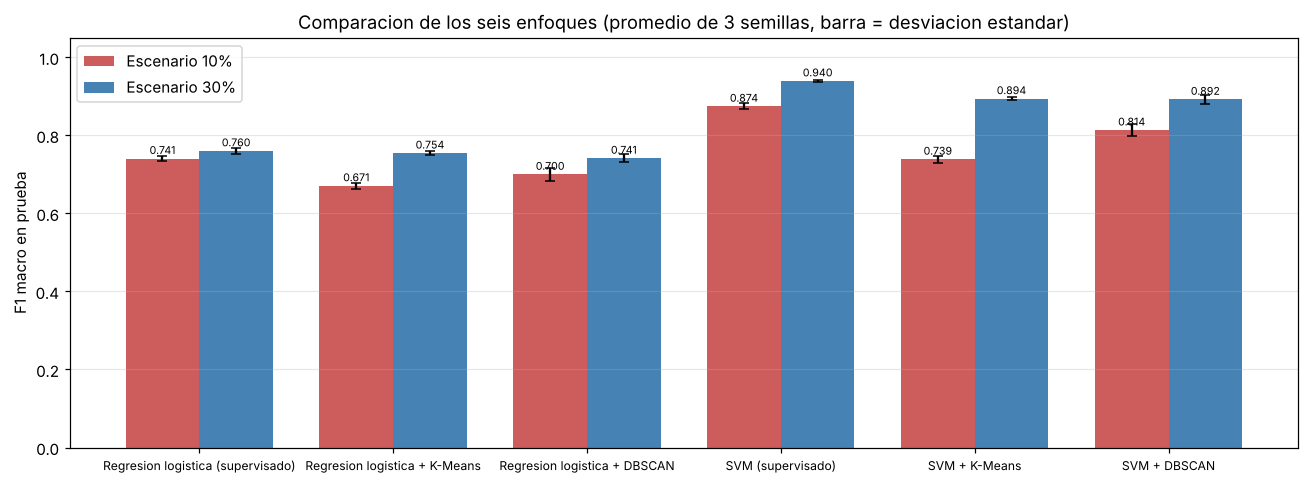

In [16]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ancho = 0.38
for j, esc in enumerate(ESCENARIOS):
    sub = resumen_test.loc[esc]
    barras = ax.bar(np.arange(len(sub)) + (j - 0.5) * ancho, sub['F1_test'], ancho,
                    yerr=sub['F1_test_std'], capsize=3, label=f'Escenario {esc}', color=colores[esc])
    for b, v in zip(barras, sub['F1_test']):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f'{v:.3f}', ha='center', fontsize=7)
ax.set_xticks(np.arange(len(sub)), sub.index, fontsize=8)
ax.set_ylabel('F1 macro en prueba')
ax.set_ylim(0, 1.05)
ax.set_title('Comparacion de los seis enfoques (promedio de 3 semillas, barra = desviacion estandar)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Diferencia de cada enfoque semisupervisado respecto de su version supervisada, por semilla
base = df_test[df_test['Enfoque'] == 'Supervisado'].set_index(['Semilla', 'Escenario', 'Clasificador'])['F1 macro test']
semi = df_test[df_test['Enfoque'] != 'Supervisado'].copy()
semi['Diferencia vs supervisado'] = semi['F1 macro test'].values - base.loc[
    list(zip(semi['Semilla'], semi['Escenario'], semi['Clasificador']))].values
calidad = df_clu[df_clu['Elegida']][['Semilla', 'Escenario', 'Tecnica', 'Precision real (diagnostico)', 'Cobertura total']]
semi = semi.merge(calidad, left_on=['Semilla', 'Escenario', 'Enfoque'], right_on=['Semilla', 'Escenario', 'Tecnica'])

tabla_dif = (semi.groupby(['Escenario', 'Nombre'], sort=False)
             .agg(Diferencia_media=('Diferencia vs supervisado', 'mean'),
                  Diferencia_min=('Diferencia vs supervisado', 'min'),
                  Diferencia_max=('Diferencia vs supervisado', 'max'),
                  Precision_pseudo=('Precision real (diagnostico)', 'mean'),
                  Cobertura=('Cobertura total', 'mean')))
tabla_dif

Diferencia_media  Diferencia_min  \
Escenario Nombre                                                            
10%       Regresion logistica + K-Means           -0.0699         -0.0780   
          Regresion logistica + DBSCAN            -0.0406         -0.0520   
          SVM + K-Means                           -0.1357         -0.1402   
          SVM + DBSCAN                            -0.0609         -0.0725   
30%       Regresion logistica + K-Means           -0.0059         -0.0085   
          Regresion logistica + DBSCAN            -0.0190         -0.0230   
          SVM + K-Means                           -0.0455         -0.0483   
          SVM + DBSCAN                            -0.0472         -0.0627   

                                         Diferencia_max  Precision_pseudo  \
Escenario Nombre                                                            
10%       Regresion logistica + K-Means         -0.0570            0.7938   
          Regresion logistica + DBSCAN          -0.0293            0.8447   
          SVM + K-Means                         -0.1312            0.7938   
          SVM + DBSCAN                          -0.0482            0.8447   
30%       Regresion logistica + K-Means         -0.0012            0.8809   
          Regresion logistica + DBSCAN          -0.0162            0.8784   
          SVM + K-Means                         -0.0436            0.8809   
          SVM + DBSCAN                          -0.0394            0.8784   

                                         Cobertura  
Escenario Nombre                                    
10%       Regresion logistica + K-Means     0.6000  
          Regresion logistica + DBSCAN      0.3786  
          SVM + K-Means                     0.6000  
          SVM + DBSCAN                      0.3786  
30%       Regresion logistica + K-Means     0.6000  
          Regresion logistica + DBSCAN      0.5450  
          SVM + K-Means                     0.6000  
          SVM + DBSCAN                      0.5450

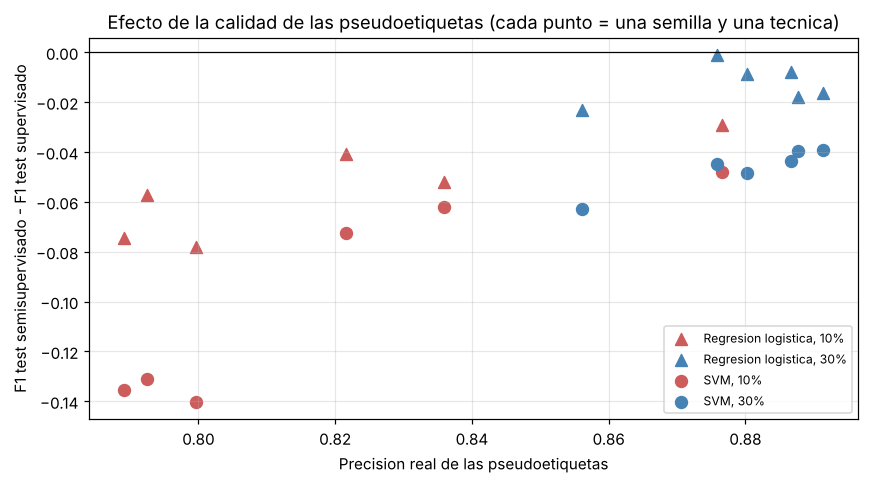

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (clf, esc), sub in semi.groupby(['Clasificador', 'Escenario']):
    ax.scatter(sub['Precision real (diagnostico)'], sub['Diferencia vs supervisado'],
               marker='o' if clf == 'SVM' else '^', color=colores[esc], s=60, label=f'{clf}, {esc}')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Precision real de las pseudoetiquetas')
ax.set_ylabel('F1 test semisupervisado - F1 test supervisado')
ax.set_title('Efecto de la calidad de las pseudoetiquetas (cada punto = una semilla y una tecnica)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Análisis de sensibilidad: cantidad frente a calidad de las pseudoetiquetas

Los resultados anteriores muestran que el pseudoetiquetado empeoró el desempeño, pero no explican en qué momento empieza a hacerlo. Para eso repetimos la validación cruzada variando cuántas pseudoetiquetas se agregan (0, 1.000, 2.000, 4.000 y 8.000), siempre tomando primero las de mayor confianza. Usamos la semilla 0, las configuraciones de clustering elegidas y un hiperparámetro fijo por clasificador: `C = 1` en la regresión logística y RBF con `C = 10` en la SVM. Cero pseudoetiquetas equivale al enfoque supervisado.

Igual que antes, el desempeño se mide solo con las etiquetas reales de los folds de validación, y la precisión real de las pseudoetiquetas se muestra solo como diagnóstico.

In [19]:
CANTIDADES = [0, 1000, 2000, 4000, 8000]
MODELOS_SENS = {'Regresion logistica': LogisticRegression(C=1, max_iter=3000),
                'SVM': SVC(kernel='rbf', C=10, gamma='scale')}
semilla = SEMILLAS[0]
registro_sens = []
inicio = time.time()

for esc, frac in ESCENARIOS.items():
    idx_lab = elegir_etiquetados(frac, semilla)
    y_lab = y_train[idx_lab]
    particiones = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla).split(idx_lab, y_lab))
    for tecnica in ('K-Means', 'DBSCAN'):
        conf = df_clu[(df_clu['Semilla'] == semilla) & (df_clu['Escenario'] == esc)
                      & (df_clu['Tecnica'] == tecnica) & df_clu['Elegida']]['Configuracion'].iloc[0]
        info = infos_kmeans[semilla][conf] if tecnica == 'K-Means' else infos_dbscan[conf]
        for n_ps in CANTIDADES:
            folds_n, n_reales, precisiones = [], [], []
            for a, b in particiones:
                tr, va = idx_lab[a], idx_lab[b]
                sel, etq, _ = pseudoetiquetar(info, tr, y_train[tr], n_ps, excluir=va)
                folds_n.append((np.r_[tr, sel], np.r_[y_train[tr], etq], va))
                n_reales.append(len(sel))
                if len(sel):
                    precisiones.append((etq == y_train[sel]).mean())
            for clasificador, modelo in MODELOS_SENS.items():
                res = Parallel(n_jobs=-1)(delayed(evaluar_fold)(modelo, f, yf, v) for f, yf, v in folds_n)
                registro_sens.append({
                    'Escenario': esc, 'Tecnica': tecnica, 'Configuracion': conf, 'Clasificador': clasificador,
                    'Pedidas': n_ps, 'Pseudoetiquetas': np.mean(n_reales),
                    'Precision real pseudo': np.mean(precisiones) if precisiones else np.nan,
                    'F1 macro CV': np.mean([r[0] for r in res])})

df_sens = pd.DataFrame(registro_sens)
print(f'Analisis de sensibilidad listo en {time.time() - inicio:.0f} s')
tabla_sens = df_sens.pivot_table(index=['Escenario', 'Tecnica', 'Pedidas'], columns='Clasificador',
                                 values='F1 macro CV')
tabla_sens.columns = [f'F1 CV {c}' for c in tabla_sens.columns]
tabla_sens.join(df_sens.groupby(['Escenario', 'Tecnica', 'Pedidas'])[['Pseudoetiquetas', 'Precision real pseudo']].first())

Analisis de sensibilidad listo en 47 s


F1 CV Regresion logistica  F1 CV SVM  \
Escenario Tecnica Pedidas                                         
10%       DBSCAN  0                           0.7460     0.8626   
                  1000                        0.7394     0.8689   
                  2000                        0.7365     0.8694   
                  4000                        0.6741     0.8020   
                  8000                        0.6741     0.8020   
          K-Means 0                           0.7460     0.8626   
                  1000                        0.7434     0.8699   
                  2000                        0.7299     0.8369   
                  4000                        0.6979     0.7881   
                  8000                        0.6639     0.7312   
30%       DBSCAN  0                           0.7595     0.9291   
                  1000                        0.7611     0.9281   
                  2000                        0.7607     0.9281   
                  4000                        0.7311     0.8763   
                  8000                        0.7317     0.8763   
          K-Means 0                           0.7595     0.9291   
                  1000                        0.7652     0.9278   
                  2000                        0.7593     0.9212   
                  4000                        0.7448     0.8785   
                  8000                        0.7174     0.8118   

                           Pseudoetiquetas  Precision real pseudo  
Escenario Tecnica Pedidas                                          
10%       DBSCAN  0                 0.0000                    NaN  
                  1000          1,000.0000                 1.0000  
                  2000          2,000.0000                 1.0000  
                  4000          3,938.6000                 0.8650  
                  8000          3,938.6000                 0.8650  
          K-Means 0                 0.0000                    NaN  
                  1000          1,000.0000                 0.9942  
                  2000          2,000.0000                 0.9658  
                  4000          4,000.0000                 0.8871  
                  8000          8,000.0000                 0.7870  
30%       DBSCAN  0                 0.0000                    NaN  
                  1000          1,000.0000                 1.0000  
                  2000          2,000.0000                 1.0000  
                  4000          3,769.6000                 0.8803  
                  8000          3,779.8000                 0.8796  
          K-Means 0                 0.0000                    NaN  
                  1000          1,000.0000                 0.9980  
                  2000          2,000.0000                 0.9822  
                  4000          4,000.0000                 0.9041  
                  8000          7,529.4000                 0.8108

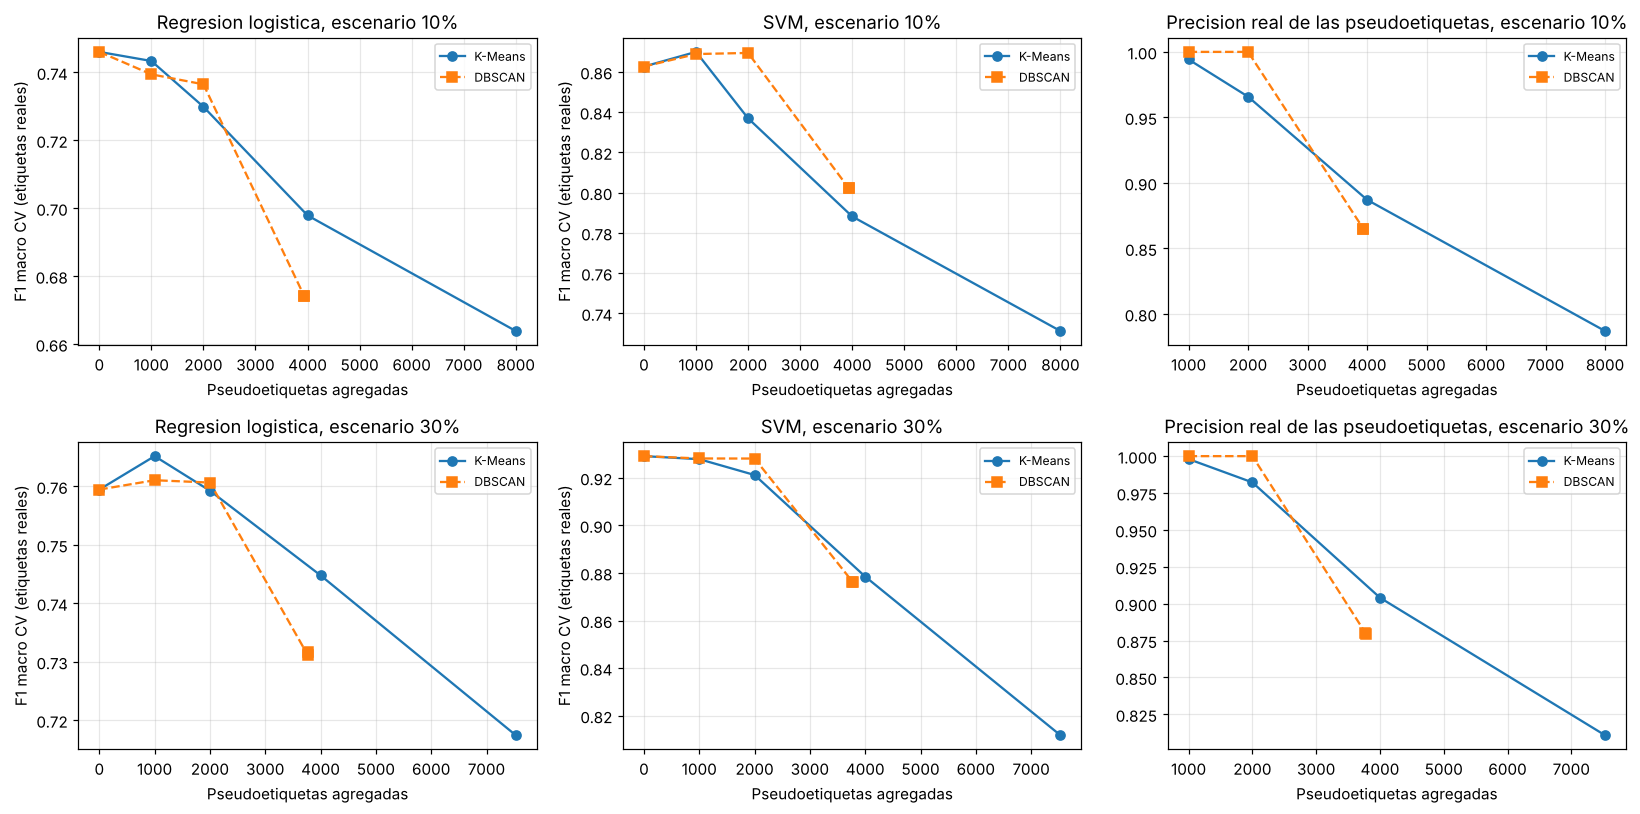

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
estilos = {'K-Means': ('o', '-'), 'DBSCAN': ('s', '--')}
for fila, esc in zip(axes, ESCENARIOS):
    for tecnica, (mk, ls) in estilos.items():
        sub = df_sens[(df_sens['Escenario'] == esc) & (df_sens['Tecnica'] == tecnica)]
        for ax, clasificador in zip(fila[:2], MODELOS_SENS):
            s = sub[sub['Clasificador'] == clasificador]
            ax.plot(s['Pseudoetiquetas'], s['F1 macro CV'], marker=mk, ls=ls, label=tecnica)
            ax.set_title(f'{clasificador}, escenario {esc}')
            ax.set_ylabel('F1 macro CV (etiquetas reales)')
        s = sub[(sub['Clasificador'] == 'SVM') & (sub['Pedidas'] > 0)]
        fila[2].plot(s['Pseudoetiquetas'], s['Precision real pseudo'], marker=mk, ls=ls, label=tecnica)
        fila[2].set_title(f'Precision real de las pseudoetiquetas, escenario {esc}')
    for ax in fila:
        ax.set_xlabel('Pseudoetiquetas agregadas')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Análisis de sensibilidad

Este experimento explica por qué el pseudoetiquetado no ayudó.

Las primeras pseudoetiquetas son casi perfectas, pero aportan poco. Las primeras 1.000 tienen una precisión de entre 99 % y 100 % y cambian el F1 en menos de 0,01, a veces hacia arriba y a veces hacia abajo. Son los puntos más cercanos al centro de clusters puros, es decir, ejemplos fáciles que el clasificador ya sabía clasificar con los datos etiquetados, así que no le entregan información nueva. Con DBSCAN la precisión se mantiene en 100 % hasta las 2.000 pseudoetiquetas y el F1 tampoco cambia.

Incluso pocos errores afectan a la SVM. Con K-Means, al llegar a 2.000 pseudoetiquetas la precisión baja a entre 96 % y 98 %, y el F1 de la SVM ya cae 0,026 puntos en el escenario del 10 %.

Al seguir agregando, la calidad cae de forma brusca. Para acercarse al 60 % hay que usar puntos de la periferia de los clusters en K-Means, o puntos borde en DBSCAN. En DBSCAN con 10 % de etiquetados, las primeras 2.000 pseudoetiquetas tienen 100 % de precisión, pero las aproximadamente 1.900 siguientes tienen solo alrededor de 73 %, lo que baja la precisión total a 86,5 %. Justo en ese tramo el F1 cae entre 0,03 y 0,07 puntos.

Además, los errores de las pseudoetiquetas no son ruido aleatorio, sino sistemáticos. Cuando un cluster mezcla dos letras parecidas, todos sus puntos mal etiquetados reciben la misma letra equivocada, y además se ubican cerca de la frontera entre ambas clases. Eso desplaza la frontera del clasificador justo donde más cuesta decidir.

La SVM es la más perjudicada, porque con sus fronteras flexibles se ajusta también a las pseudoetiquetas incorrectas. La regresión logística, más rígida, se ve menos afectada: con 8.000 pseudoetiquetas de K-Means pierde 0,08 puntos de F1 en el escenario del 10 %, mientras que la SVM pierde 0,13.

En resumen, el objetivo del 60 % obliga a incluir pseudoetiquetas de baja calidad. Hay un compromiso directo entre cantidad y calidad, y con este dataset la calidad pesa más.

## 12. Conclusiones

**El mejor enfoque es la SVM supervisada en ambos escenarios.** Obtiene un F1 macro de 0,875 con el 10 % de etiquetas y de 0,940 con el 30 %. Ningún enfoque semisupervisado superó a su versión supervisada en ninguna semilla, y como las desviaciones estándar entre semillas son pequeñas (menores a 0,02), la conclusión no depende de la semilla.

**Calidad de las pseudoetiquetas.** El pseudoetiquetado solo puede ayudar si las etiquetas que agrega son más confiables que lo que el clasificador ya predice por sí mismo. En el escenario del 10 %, la SVM supervisada se equivoca en cerca del 12 % de los casos, mientras que las pseudoetiquetas se equivocan en un 21 % con K-Means y en un 16 % con DBSCAN. Agregarlas equivale a entrenar con datos peores que el propio modelo, y por eso la SVM con K-Means pierde 0,136 puntos de F1. La regresión logística se equivoca cerca del 26 %, así que para ella las pseudoetiquetas sí son algo más precisas que el modelo, pero igual la perjudican porque sus errores son sistemáticos (sección 11). Entre técnicas, DBSCAN asignó menos pseudoetiquetas pero de mejor calidad, y por eso perdió menos que K-Means en el escenario del 10 % con ambos clasificadores.

**Cantidad de etiquetas reales.** Pasar del 10 % al 30 % de etiquetas reales mejora todo a la vez: el F1 de la SVM supervisada sube de 0,875 a 0,940, la precisión de las pseudoetiquetas de K-Means sube de 79 % a 88 % y se necesitan menos pseudoetiquetas. Por eso la pérdida de los enfoques semisupervisados se reduce mucho, y en el escenario del 30 % la regresión logística con K-Means queda prácticamente empatada con su versión supervisada, con una diferencia de 0,006. Aquí aparece una paradoja: el aprendizaje semisupervisado haría más falta cuando hay pocas etiquetas, pero es justo en ese caso cuando las pseudoetiquetas son peores.

**Hiperparámetros.** La elección del modelo y de sus hiperparámetros influye más que el uso de pseudoetiquetas. La SVM con kernel RBF supera ampliamente a la regresión logística en todos los casos, al punto de que la SVM con DBSCAN, aun perjudicada por las pseudoetiquetas, obtiene 0,814 en el escenario del 10 % y supera a la regresión logística supervisada, que obtiene 0,741. En la regresión logística, solo una regularización excesiva (`C = 0,01`) empeora claramente el resultado.

**Por qué falla el supuesto semisupervisado.** El pseudoetiquetado con clustering supone que los puntos de un mismo grupo comparten la misma clase. En este dataset ese supuesto se cumple solo en parte: la silueta es baja (menor a 0,2), K-Means con un cluster por letra tiene una pureza muy baja y DBSCAN no encuentra regiones densas que separen las letras. Las 26 letras no forman grupos naturales en el espacio de las 16 características, porque cada una aparece en 20 tipografías distintas y varias se parecen entre sí. La conclusión no es que el aprendizaje semisupervisado no sirva, sino que depende de que la estructura de los clusters coincida con la de las clases, y aquí no coincide.

**La validación cruzada fue un buen criterio.** Sin usar el conjunto de prueba ni las etiquetas desconocidas, la validación cruzada mostró que los enfoques semisupervisados rendían menos, y el conjunto de prueba lo confirmó. En una aplicación real, este procedimiento nos habría llevado a elegir el modelo supervisado.

**Posibles mejoras.** Hay algunas alternativas que podrían hacer que el pseudoetiquetado sí aporte. Una es darle menos peso a las pseudoetiquetas durante el entrenamiento. Otra es aceptar una cobertura menor al 60 % y quedarse solo con las pseudoetiquetas de alta confianza, que según el análisis de sensibilidad son las que no dañan al modelo. Una tercera es combinar el cluster con la predicción del propio clasificador y aceptar una pseudoetiqueta solo cuando ambos coinciden, en la línea del *self-training*.